<a href="https://colab.research.google.com/github/marcelfollyagbo1-ui/panier-perdu/blob/main/untitled0_ipynbportfolio_finance_voo_qqq_aapl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Ticker            AAPL         QQQ         VOO
Date                                          
2026-10-26  343.910004  712.200012  703.409973
2026-10-27  347.100006  721.250000  707.520020
2026-10-28  343.829987  725.609985  709.900024
2026-10-29  348.910004  715.340027  707.320007
2026-10-30  344.630005  690.489990  694.809998


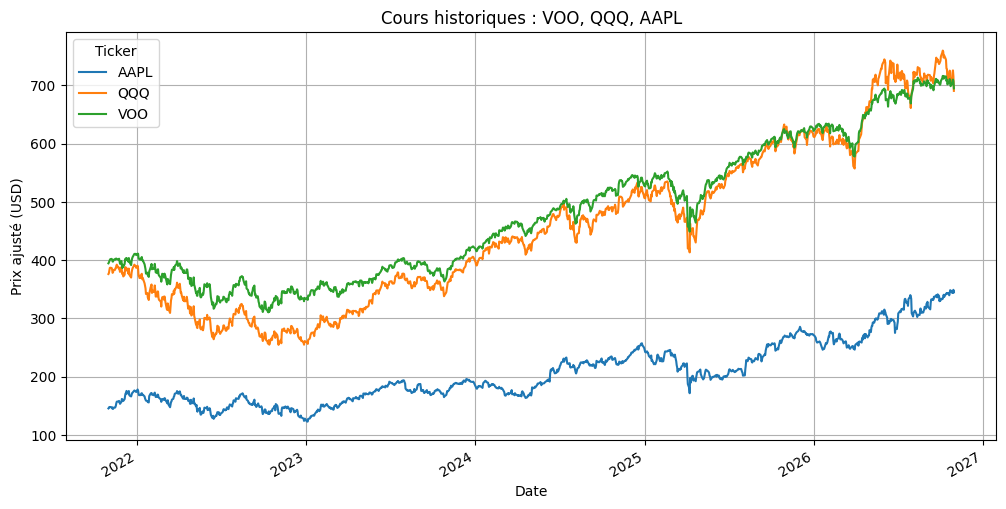

In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt

actifs = ["VOO", "QQQ", "AAPL"]

cours = yf.download(actifs, period="5y", auto_adjust=True, progress=False)["Close"]
cours = cours.dropna(how="all")

print(cours.tail())

cours.plot(figsize=(12, 6))
plt.title("Cours historiques : VOO, QQQ, AAPL")
plt.ylabel("Prix ajusté (USD)")
plt.grid(True)
plt.show()


In [ ]:
rendement_cumule = (indices.iloc[-1] / 100 - 1) * 100
print(rendement_cumule.round(1).astype(str) + " %")

Ticker
AAPL    137.2 %
QQQ      83.6 %
VOO      76.2 %
Name: 2026-10-30 00:00:00, dtype: object


In [ ]:
rendement_cumule = (indices.iloc[-1] / 100 - 1) * 100
print(rendement_cumule.round(1).astype(str) + " %")

Ticker
AAPL    137.2 %
QQQ      83.6 %
VOO      76.2 %
Name: 2026-10-30 00:00:00, dtype: object


In [ ]:
import numpy as np

rendements = cours.pct_change().dropna()

volatilite = rendements.std() * np.sqrt(252) * 100

print("Volatilité annualisée :")
print(volatilite.round(1).astype(str) + " %")

Volatilité annualisée :
Ticker
AAPL    28.0 %
QQQ     23.1 %
VOO     16.9 %
dtype: object


In [ ]:
valeurs = (1 + rendements).cumprod()
sommets = valeurs.cummax()
drawdowns = valeurs / sommets - 1

drawdown_max = drawdowns.min() * 100

print("Drawdown maximal :")
print(drawdown_max.round(1).astype(str) + " %")

Drawdown maximal :
Ticker
AAPL    -33.4 %
QQQ     -35.1 %
VOO     -24.5 %
dtype: object


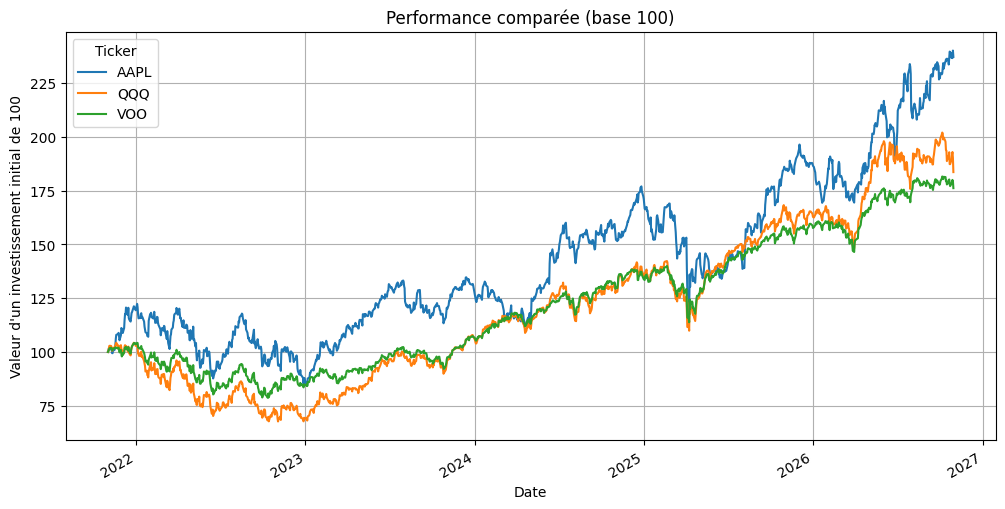

In [ ]:
base = cours.iloc[0]
indices = cours.div(base).mul(100)

indices.plot(figsize=(12, 6))
plt.title("Performance comparée (base 100)")
plt.ylabel("Valeur d'un investissement initial de 100")
plt.grid(True)
plt.show()

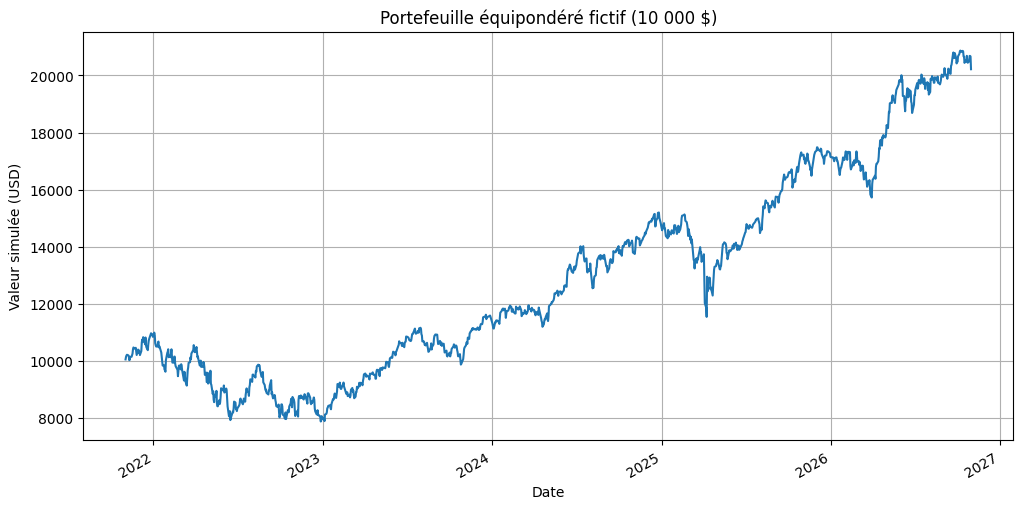

Valeur finale : 20219.0 USD


In [ ]:
import pandas as pd

capital = 10_000

# Portefeuille équipondéré : un tiers dans chaque actif
rendement_portefeuille = rendements.mean(axis=1)

valeur_portefeuille = capital * (1 + rendement_portefeuille).cumprod()

valeur_portefeuille.plot(figsize=(12, 6))
plt.title("Portefeuille équipondéré fictif (10 000 $)")
plt.ylabel("Valeur simulée (USD)")
plt.grid(True)
plt.show()

print("Valeur finale :", round(valeur_portefeuille.iloc[-1], 0), "USD")